# *Ben Wisinski*
## **10/21/2026**
## **"API DATA REPORT**

### Hypothesis
My hypothesis is that posts with links have less engagement due to linking users away from the original post. However, counterintuitively to my previous statement I feel that posts with the most amount of links are ones by accounts with the most amount of followers.

### Required Variables
To test my hypothesis, I need the combined engagement. Data of repost likes in comments. As well as follower account. I will also need a variable that swords through and divide posts that do you have a link and do not have a link within them.

### Usecase
This experiment would be good to see whether it is actually useful for big companies to be posting links to other webpages on their social media page, as well as if when it is reposted by a smaller user if they still gain the same level engagement.

### The Two Used APIs

/app.bsky.feed.SEARCHPOSTS

I will use this API in order to gain a list of posts that are random from different users that contain common words by doing this I hope to obtain the most unbiased and random assortment of user posts. I will most likely have to not sort by latest as if I do, then they will not have had time to get engagement and therefore the results will be skewed. I also will not have access to follow account through this method and will not be able to explore more in depth of a single user outside of that post data.

/app.bsky.actor.getProfiles

Through this API, I hope to gain more information about the user and their followers. This obviously comes at the price of not being able to see other users posts because this is more focused on a specific users. 

In [1]:
import requests
import pandas as pd

Base = "https://public.api.bsky.app/xrpc"

Used import requests to be able to inquiry webpages. Use import pandas to import pandas. And set the base URL for the blue sky, API as base variable.

In [2]:
common_words = ["the", "and", "I", "you", "my", "new", "we", "show","work"]

posts = []

for word in common_words:
    params = {
        "q": word,
        "sort": "top",
        "limit": 100
    }

    response = requests.get(
        Base + "/app.bsky.feed.SEARCHPOSTS", 
        params=params
    )
    
    print(word, response.status_code)

    if response.status_code == 200:
        data = response.json()
        posts.extend(data["posts"])
   
print("Total posts collected:", len(posts))

the 200
and 200
I 200
you 200
my 200
new 200
we 200
show 200
work 200
Total posts collected: 898


I first use a array to put a bunch of different common search words into a variable, then create a empty array "posts" to put my eventual found data into.

I then use a loop to set the parameters by using the variable common words to search individually for the latest posts with a limit of 100 pages. 

I then use the request.get to get data by searching for and finding posts that fit the parameters previously set.

I then print the response status code to make sure that my requests are actively going through if they return 200 then they convert the data into json file. Then adds all of the information into the posts array.

Finally, I print the total number of post collected using length with the posts array



In [6]:
posts_list = []

for post in posts:
    record = post.get("record", {})
    post_text = record.get("text", "")
    facets = record.get("facets", [])
    embed = post.get("embed", {})

    has_link = (
    "http://" in post_text
    or any(
        feature.get("$type") == "app.bsky.richtext.facet#link"
        for facet in facets
        for feature in facet.get("features", [])
    )
    or embed.get("$type") == "app.bsky.embed.external#view"
    )

    posts_list.append({
        "post_uri": post.get("uri"),
        "Account": post.get("author", {}).get("handle"),
        "author_did": post.get("author", {}).get("did"),
        "text": post_text,
        "Date": record.get("createdAt"),
        "has_link": has_link,
        "likes": post.get("likeCount", 0),
        "reposts": post.get("repostCount", 0),
        "replies": post.get("replyCount", 0)
    })

posts_df = pd.DataFrame(posts_list)

posts_df = posts_df.drop_duplicates(subset="post_uri")

posts_df.head()

,post_uri,Account,author_did,text,Date,has_link,likes,reposts,replies
0,at://did:plc:e72cwu7fen37hzzzhwy6mkxp/app.bsky...,hausofdecline.bsky.social,did:plc:e72cwu7fen37hzzzhwy6mkxp,The popular monsters of the era reflect the cu...,2026-10-21T03:16:47.634Z,False,6610,905,70
1,at://did:plc:udnac33pmf2iwcblpeai5a5p/app.bsky...,iwillnotbesilenced.bsky.social,did:plc:udnac33pmf2iwcblpeai5a5p,The moment City Council gets it right and pass...,2026-10-21T11:37:35.977Z,False,7191,2158,148
2,at://did:plc:qlxgxm7fqszfgowm347s2q4t/app.bsky...,beetlemoses.bsky.social,did:plc:qlxgxm7fqszfgowm347s2q4t,,2026-10-20T20:25:17.325Z,False,6652,857,64
3,at://did:plc:u44je2xqdeb33u3rmy4457yg/app.bsky...,jake2404663.bsky.social,did:plc:u44je2xqdeb33u3rmy4457yg,The fucking idiot in the White House picked th...,2026-10-20T15:49:40.454Z,False,9096,1534,238
4,at://did:plc:s5b3x4exyludm73jcgvupe7q/app.bsky...,kylegriffin1.bsky.social,did:plc:s5b3x4exyludm73jcgvupe7q,BREAKING WSJ:\n\nElon Musk ordered the slowdow...,2026-10-20T20:30:20.037Z,True,5661,2485,751


For the cell I created a empty array called posts_list I then created a set of variables and filled them with information from the post using .get this information included record information post text faces, which are essentially blue sky's name for different element. Elements included in a post and embedded elements. 

For the syntax around "$type", "app.bsky.richtext.facet#link" and "app.bsky.embed.external#view" I used AI to help me find the correct way of calling.

Once that was done, I then created a separate variable that searched for any use of the letter combination "http:/" within the different variables that I had previously pulled out. Essentially what this does is searches for any links that are potentially included within a any of the posts.

And then use .append to organize all of this information into variables that can be added to posts_lists and then called to create a data frame.

Then using the drop duplicates, I filter out any posts with the same URI

In [10]:
print ("unique posts:", len(posts_df))
print("posts with  links:", posts_df["has_link"].sum())
print("posts without links:", (-posts_df["has_link"]).sum())

unique posts: 873
posts with  links: 44
posts without links: 829


Used this to quickly see how many unique posts I have and how many have links and do not. It's quite a parent already that there are many more posts with out links than there are with links, so I will most likely need to take a proportional approach to how I analyze this data.


In [15]:
posts_df["total engagement"] = (
    posts_df["likes"]
    + posts_df["reposts"]
    + posts_df["replies"]
)

engagement_comparison = posts_df.groupby("has_link")[
    ["likes", "reposts", "replies", "total engagement"]
].mean()

engagement_comparison

,likes,reposts,replies,total engagement
has_link,,,,
False,2004.541616,424.096502,83.150784,2511.788902
True,2524.250000,771.477273,118.795455,3414.522727


And then create a variable called total engagement, which combines likes repost and replies. Then I use the has_link group to create a data frame called engagement comparison, which will compare the mean value of likes repost, replies, and total engagement crossed all posts while splitting it into having a link and not having a link

In [16]:
authors = posts_df["author_did"].dropna().unique().tolist()

print("Unique authors:", len(authors))

Unique authors: 634


This alows to sort and drop repeated authors so i have an idea of how many unique authors there are.

.dropna().unique().tolist() sourced via Ai

In [17]:
profiles_list = []

for i in range(0, len(authors), 25):
    author_batch = authors[i:i + 25]

    params = [
        ("actors", author)
        for author in author_batch
    ]

    response = requests.get(
        Base + "/app.bsky.actor.getProfiles",
        params=params
    )

    print(response.status_code)

    if response.status_code == 200:
        data = response.json()
        profiles_list.extend(data["profiles"])

200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200
200


In the cell, I take a empty array and using arrange to call multiple authors at the same time fill it with information from the .getprofiles endpoint once that is done, I check the status and if it is available, then I created a json file fillied with the profile info

In [18]:
profiles_df = pd.DataFrame([
    {
        "author_did": profile.get("did"),
        "followers": profile.get("followersCount", 0)
    }
    for profile in profiles_list
])

profiles_df.head()

,author_did,followers
0,did:plc:e72cwu7fen37hzzzhwy6mkxp,269807
1,did:plc:udnac33pmf2iwcblpeai5a5p,84908
2,did:plc:qlxgxm7fqszfgowm347s2q4t,129326
3,did:plc:u44je2xqdeb33u3rmy4457yg,49097
4,did:plc:s5b3x4exyludm73jcgvupe7q,325891


Created a new data frame to populate with information gained from in the profile_list array

In [66]:
posts_df = posts_df.drop(
    columns=["followers"],
)

posts_df = posts_df.merge(
    profiles_df,
    on="author_did",
    how="left"
)

posts_df.head()

,post_uri,Account,author_did,text,Date,has_link,likes,reposts,replies,engagement,total engagement,followers
0,at://did:plc:e72cwu7fen37hzzzhwy6mkxp/app.bsky...,hausofdecline.bsky.social,did:plc:e72cwu7fen37hzzzhwy6mkxp,The popular monsters of the era reflect the cu...,2026-10-21T03:16:47.634Z,False,6610,905,70,7585,7585,269807
1,at://did:plc:udnac33pmf2iwcblpeai5a5p/app.bsky...,iwillnotbesilenced.bsky.social,did:plc:udnac33pmf2iwcblpeai5a5p,The moment City Council gets it right and pass...,2026-10-21T11:37:35.977Z,False,7191,2158,148,9497,9497,84908
2,at://did:plc:qlxgxm7fqszfgowm347s2q4t/app.bsky...,beetlemoses.bsky.social,did:plc:qlxgxm7fqszfgowm347s2q4t,,2026-10-20T20:25:17.325Z,False,6652,857,64,7573,7573,129326
3,at://did:plc:u44je2xqdeb33u3rmy4457yg/app.bsky...,jake2404663.bsky.social,did:plc:u44je2xqdeb33u3rmy4457yg,The fucking idiot in the White House picked th...,2026-10-20T15:49:40.454Z,False,9096,1534,238,10868,10868,49097
4,at://did:plc:s5b3x4exyludm73jcgvupe7q/app.bsky...,kylegriffin1.bsky.social,did:plc:s5b3x4exyludm73jcgvupe7q,BREAKING WSJ:\n\nElon Musk ordered the slowdow...,2026-10-20T20:30:20.037Z,True,5661,2485,751,8897,8897,325891


Used .drop to remove the overlapping followers column, then merged the profiles_df with the posts_df

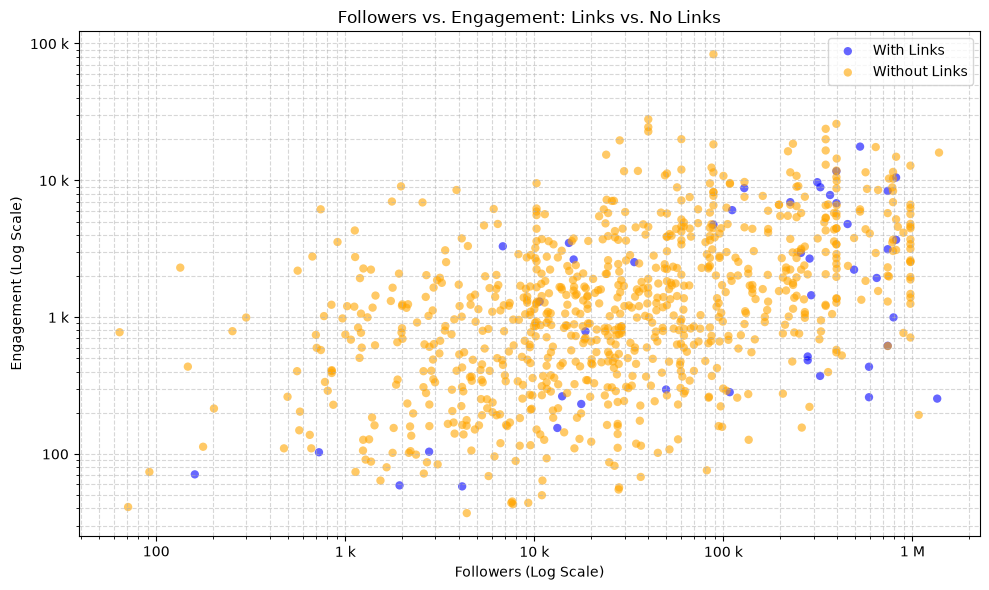

In [68]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker


with_links = posts_df[posts_df["has_link"] == True]
no_links = posts_df[posts_df["has_link"] == False]

plt.figure(figsize=(10, 6))


plt.scatter(with_links["followers"], with_links["engagement"], 
            alpha=0.6, color='blue', label='With Links', edgecolors='none')

plt.scatter(no_links["followers"], no_links["engagement"], 
            alpha=0.6, color='orange', label='Without Links', edgecolors='none')


plt.xscale('log')
plt.yscale('log') 


plt.gca().xaxis.set_major_formatter(ticker.EngFormatter())
plt.gca().yaxis.set_major_formatter(ticker.EngFormatter())


plt.xlabel("Followers (Log Scale)")
plt.ylabel("Engagement (Log Scale)")
plt.title("Followers vs. Engagement: Links vs. No Links")

plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.5) 
plt.tight_layout()
plt.show()


Then with the help of AI I found the syntax in order to create a scatter chart that scales to fit in outliers, while still being readable in order to plot all of the data that I have gained I plotted engagement along the Y axis and followers along the X axis, I have two different charts plotted on the same graph the blue one being post that were made with links and the yellow one being post that were made without links

## Results

In conclusion, I think that I have to some extent proven both of my hypothesis is to be correct as we can see in the grouping of the chart above. There are much viewer posts with links from smaller users, and when they are posted, the engagement is very low. Compare that to the users who posted links to big following, and you see that their engagement is very high and posts much more frequent. This is also backed up by the fact that even when smaller users are posting without links, they are getting consistently more engagement than the posts with links.

## Reflection 
This data is taken from a relatively small sample size of top posts, so it does not include a extremely large wide range of different posts. This also does not count for the time posted in order to allow time for engagement. In addition to this this chart has no way of differentiating between individual users versus a corporate or company account. On top of this due to the relatively small sample size it was hard to gain multiple instances of posts from the same user. There's most likely a more mathematical solution to get percentages however, I do not know the means in which I would go about doing this so I stopped making a graph.

## AI Disclamer

While I thought through the process and developed the strategy in order to do all of this on my own. There are plenty of instances of syntax and varible terms that I had help with through AI.
